In [22]:
!pip install --upgrade binance-historical-data plotly -q

In [23]:
import os
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime, timedelta, date, time
from binance_historical_data import BinanceDataDumper
warnings.filterwarnings('ignore')

def get_list_all_trading_pairs():
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",  # spot, um, cm
        data_type="klines",  # aggTrades, klines, trades
        data_frequency="5m",
    )
    return data_dumper.get_list_all_trading_pairs()

def detect_timestamp_unit(timestamp):
    num_digits = len(str(timestamp))
    if num_digits == 13:
        return 'ms'
    elif num_digits == 16:
        return 'us'
    else:
        raise ValueError(f"Timestamp không hợp lệ: {timestamp}")

def convert_timestamp(timestamp):
    unit = detect_timestamp_unit(timestamp)
    return pd.to_datetime(timestamp, unit=unit, errors='coerce')

def download_ticker(ticker, date_start, date_end, data_frequency="1h"):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency= data_frequency,
    )
    date_start = datetime.strptime(date_start, "%Y-%m-%d").date()
    date_end = datetime.strptime(date_end, "%Y-%m-%d").date()
    data_dumper.dump_data(
        tickers = ticker,
        date_start = date_start,
        date_end = date_end,
        is_to_update_existing = False,
    )

def read_csv_file(file_path):
    df = pd.read_csv(file_path)
    df.columns = [
        "open_time", "Open", "High", "Low", "Close", "volume",
        "close_time", "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume", "ignore"
    ]
    df['open_time'] = df['open_time'].apply(convert_timestamp)
    df['close_time'] = df['close_time'].apply(convert_timestamp)
    return df

def get_csv_files(directory):
    try:
        if not os.path.exists(directory):
            print(f"Warning: Thư mục không tồn tại: {directory}")
            return []
        return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.csv')]
    except Exception as e:
        print(f"Lỗi khi đọc thư mục {directory}: {str(e)}")
        return []

# Load data from file
def process_csv_files(ticker, data_frequency = "1h"):
    daily_path = os.path.join(os.getcwd(), f"spot/daily/klines/{ticker}/{data_frequency}")
    monthly_path = os.path.join(os.getcwd(), f"spot/monthly/klines/{ticker}/{data_frequency}")
    daily_files = get_csv_files(daily_path)
    monthly_files = get_csv_files(monthly_path)
    all_files = daily_files + monthly_files
    if not all_files:
        print(f"❗ Không có file CSV nào cho {ticker}")
        return None
    data = pd.concat([read_csv_file(file) for file in all_files], ignore_index=True)
    data.sort_values(by='open_time', inplace=True)
    return data



In [24]:
ticker = 'BTCUSDT'
data_frequency = '5m'
download_ticker(ticker, "2024-01-01", "2025-07-25", data_frequency)
data = process_csv_files(ticker, data_frequency)
data = data.drop(columns=['close_time',	'quote_asset_volume',	'number_of_trades',	'taker_buy_base_asset_volume',	'taker_buy_quote_asset_volume',	'ignore'])
data.set_index('open_time', inplace=True)
data

---> Found overall tickers: 595
---> Filter to asked tickers: 7
------> Tickers left: 2
Download full data for 2 tickers: 
---> Data will be saved here: /content/spot
---> Data Frequency: 5m
---> Start Date: 20240101
---> End Date: 20250725


Tickers:   0%|          | 0/2 [00:00<?, ?it/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

Tried to dump data for 2 tickers:
---> For BTCUSDT new data saved for: 0 months 0 days
---> For BTCUSD new data saved for: 0 months 0 days


,Open,High,Low,Close,volume
open_time,,,,,
2024-01-01 00:05:00,42397.22,42432.74,42385.26,42409.96,141.31102
2024-01-01 00:10:00,42409.97,42488.09,42409.96,42488.00,135.14249
2024-01-01 00:15:00,42488.00,42554.57,42458.58,42458.85,163.32541
2024-01-01 00:20:00,42458.85,42491.10,42445.84,42473.93,117.27112
2024-01-01 00:25:00,42473.93,42500.00,42412.02,42419.73,111.65236
...,...,...,...,...,...
2025-07-25 23:35:00,117350.07,117571.44,117350.07,117547.58,118.58042
2025-07-25 23:40:00,117547.58,117598.26,117532.41,117532.41,31.18831
2025-07-25 23:45:00,117532.41,117599.12,117522.40,117599.12,22.83026


In [25]:
# Calculate the average of the 10-day MA High and 10-day Low
data['Mean_HL'] = (data['High'].rolling(window=10).mean()+data['Low'].rolling(window=10).mean())*0.5
data['Lower'] = data['Mean_HL']*0.985
data['Upper'] = data['Mean_HL']*1.015
data['PnL'] = 0
data['Unrealised'] = 0
data['Position'] = np.where(data['Open'] >= data['Upper'].shift(1), -1, np.where(data['Open'] <= data['Lower'].shift(1), 1, 0))

has_non_zero = (data['Position'] != 0).sum()
print("Column has non-zero:", has_non_zero)

data.head (500) # Display the DataFrame

Column has non-zero: 497


,Open,High,Low,Close,volume,Mean_HL,Lower,Upper,PnL,Unrealised,Position
open_time,,,,,,,,,,,
2024-01-01 00:05:00,42397.22,42432.74,42385.26,42409.96,141.31102,NaN,NaN,NaN,0,0,0
2024-01-01 00:10:00,42409.97,42488.09,42409.96,42488.00,135.14249,NaN,NaN,NaN,0,0,0
2024-01-01 00:15:00,42488.00,42554.57,42458.58,42458.85,163.32541,NaN,NaN,NaN,0,0,0
2024-01-01 00:20:00,42458.85,42491.10,42445.84,42473.93,117.27112,NaN,NaN,NaN,0,0,0
2024-01-01 00:25:00,42473.93,42500.00,42412.02,42419.73,111.65236,NaN,NaN,NaN,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
2024-01-02 17:20:00,45266.75,45279.68,45174.34,45185.49,173.41819,45277.6660,44598.501010,45956.830990,0,0,0
2024-01-02 17:25:00,45185.50,45231.20,45151.05,45208.01,140.10024,45281.0755,44601.859368,45960.291633,0,0,0
2024-01-02 17:30:00,45208.00,45208.01,45030.00,45075.12,248.81613,45273.6770,44594.571845,45952.782155,0,0,0


In [ ]:
for i in range(len(data)-1):
  if data['Position'][i] != data['Position'][i+1]:
    data['Unrealised'][i+1] = 0.0005
  data['PnL'][i+1] = (data['Close'][i]/data['Open'][i]-1)*data['Position'][i]

data['Real_returns'] = data['PnL']-data['Unrealised']

  # data['PnL'][i] = data.apply(profit_return(['Open'][i],['Close'][i], ['Position'][i-1]))
data.head(20)


,Open,High,Low,Close,volume,Mean_HL,Lower,Upper,PnL,Unrealised,Position,Real_returns
open_time,,,,,,,,,,,,
2024-01-01 00:05:00,42397.22,42432.74,42385.26,42409.96,141.31102,NaN,NaN,NaN,0.0,0.0,0,0.0
2024-01-01 00:10:00,42409.97,42488.09,42409.96,42488.00,135.14249,NaN,NaN,NaN,0.0,0.0,0,0.0
2024-01-01 00:15:00,42488.00,42554.57,42458.58,42458.85,163.32541,NaN,NaN,NaN,0.0,0.0,0,0.0
2024-01-01 00:20:00,42458.85,42491.10,42445.84,42473.93,117.27112,NaN,NaN,NaN,0.0,0.0,0,0.0
2024-01-01 00:25:00,42473.93,42500.00,42412.02,42419.73,111.65236,NaN,NaN,NaN,0.0,0.0,0,0.0
2024-01-01 00:30:00,42419.73,42419.73,42354.19,42362.93,77.85936,NaN,NaN,NaN,0.0,0.0,0,0.0
2024-01-01 00:35:00,42362.93,42447.82,42355.36,42447.82,149.18862,NaN,NaN,NaN,0.0,0.0,0,0.0
2024-01-01 00:40:00,42447.82,42447.82,42396.50,42441.32,92.85846,NaN,NaN,NaN,0.0,0.0,0,0.0
2024-01-01 00:45:00,42441.32,42465.52,42422.45,42422.46,59.74817,NaN,NaN,NaN,0.0,0.0,0,0.0


In [ ]:
def get_periods_per_year(freq: str) -> int:
    if freq.endswith('m'):  # phút
        minutes = int(freq[:-1])
        return int(365 * 24 * 60 / minutes)
    elif freq.endswith('h'):  # giờ
        hours = int(freq[:-1])
        return int(365 * 24 / hours)
    elif freq.endswith('d'):  # ngày
        return 365
    elif freq.endswith('w'):  # tuần
        return 52
    else:
        raise ValueError(f"Không hỗ trợ định dạng data_frequency: {freq}")

def calculate_sharpe_ratio(returns_series: pd.Series, data_frequency: str, annualized_risk_free_rate: float = 0.03) -> float:
    """
    Tính toán Sharpe Ratio hàng năm từ một chuỗi lợi nhuận theo kỳ.

    Args:
        returns_series (pd.Series): Chuỗi lợi nhuận của chiến lược theo từng kỳ.
        data_frequency (str): Tần suất của dữ liệu ('15m', '1H', '1D').
        annualized_risk_free_rate (float): Lãi suất phi rủi ro hàng năm.

    Returns:
        float: Giá trị Sharpe Ratio đã được quy đổi ra năm.
    """
    # Xử lý trường hợp không có giao dịch hoặc không có biến động
    if returns_series.std() == 0 or pd.isna(returns_series.std()):
        return 0.0

    # 1. Lấy số kỳ trong một năm
    periods_per_year = get_periods_per_year(data_frequency)

    # 2. Quy đổi lãi suất phi rủi ro ra theo từng kỳ
    rf_per_period = annualized_risk_free_rate / periods_per_year

    # 3. Tính toán Sharpe Ratio
    # Lợi nhuận trung bình mỗi kỳ trừ đi lãi suất phi rủi ro mỗi kỳ
    excess_return_mean = returns_series.mean() - rf_per_period

    # Sharpe Ratio hàng ngày = Lợi nhuận vượt trội trung bình / Độ lệch chuẩn lợi nhuận
    sharpe_ratio = excess_return_mean / returns_series.std()

    # 4. Quy đổi ra Sharpe Ratio hàng năm
    annualized_sharpe = sharpe_ratio * np.sqrt(periods_per_year)

    return annualized_sharpe

def calculate_max_drawdown(returns_series: pd.Series) -> float:
    """Tính toán Maximum Drawdown từ một chuỗi lợi nhuận."""
    equity_curve = (1 + returns_series).cumprod()
    peak = equity_curve.expanding(min_periods=1).max()
    drawdown = (equity_curve - peak) / peak
    return drawdown.min()


period_per_year = get_periods_per_year(data_frequency)
real_return = data['Real_returns']

sharpe_ratio = calculate_sharpe_ratio(real_return, data_frequency)
max_drawdown = calculate_max_drawdown(real_return)


# Calculate cumulative returns
Cumulative_Return = (1 + data['Real_returns']).cumprod()


# # Calculate Sharpe Ratio
# # Assuming risk-free rate is 0 for simplicity
# sharpe_ratio = (data['PnL'].mean() - 0.03/period_per_year) / data['PnL'].std()*np.sqrt(periods_per_year) # Annualized Sharpe Ratio

# # Calculate Drawdown
# data['Peak'] = data['Cumulative_Return'].cummax()
# data['Drawdown'] = data['Peak'] - data['Cumulative_Return']

# # Calculate Max Drawdown
# max_drawdown = data['Drawdown'].max()

# # Calculate Average Drawdown (excluding zero drawdown periods)
# average_drawdown = data[data['Drawdown'] > 0]['Drawdown'].mean()

print(f"Sharpe Ratio: {sharpe_ratio}")
print(f"Max Drawdown: {max_drawdown}")
print(f"Return: {Cumulative_Return}")

# pnls = data['PnL']
# for pnl in pnls:
#   if pnl != 0:
#     print (pnl)

Sharpe Ratio: 0.4865496305249834
Max Drawdown: -0.09854050995259578
Return: open_time
2024-01-01 00:05:00    1.000000
2024-01-01 00:10:00    1.000000
2024-01-01 00:15:00    1.000000
2024-01-01 00:20:00    1.000000
2024-01-01 00:25:00    1.000000
                         ...   
2025-07-25 23:35:00    1.140189
2025-07-25 23:40:00    1.140189
2025-07-25 23:45:00    1.140189
2025-07-25 23:50:00    1.140189
2025-07-25 23:55:00    1.140189
Name: Real_returns, Length: 164693, dtype: float64


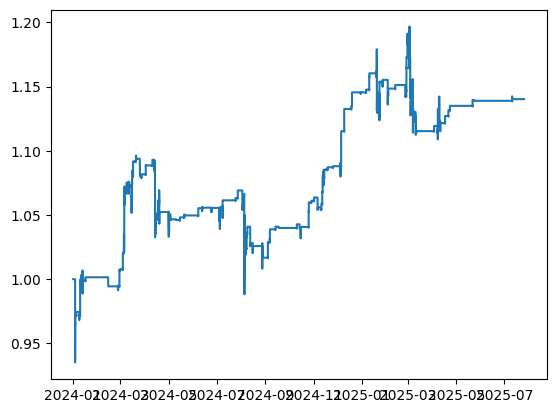

In [ ]:
dates = data.index
# Plot profit
# plt.plot(unrealised_dates, np.cumprod(1+np.array(unrealised))-1)
# plt.plot(dates, np.cumprod(1+np.array(pnls))-1)
plt.plot(dates, Cumulative_Return)
# plt.plot(unrlzd_dates,np.cumprod(1+np.array(unrlzd)))
#plt.plot(unrlzd_dates, np.cumsum(unrlzd))